<a href="https://colab.research.google.com/github/rebeccamanzini/alzheimers-drug-discovery/blob/main/notebooks/ad_transcriptomics_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
if (!requireNamespace("BiocManager", quietly = TRUE)) install.packages("BiocManager")
BiocManager::install(c("GEOquery", "limma"), update = FALSE, ask = FALSE)
install.packages(c("ggplot2", "pheatmap"))

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Installing package(s) 'BiocVersion', 'GEOquery', 'limma'

also installing the dependencies ‘XVector’, ‘matrixStats’, ‘abind’, ‘SparseArray’, ‘BiocGenerics’, ‘XML’, ‘R.oo’, ‘R.methodsS3’, ‘MatrixGenerics’, ‘GenomicRanges’, ‘IRanges’, ‘Seqinfo’, ‘S4Arrays’, ‘DelayedArray’, ‘Biobase’, ‘rentrez’, ‘R.utils’, ‘SummarizedExperiment’, ‘S4Vectors’, ‘statmod’


Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [2]:
setwd("/content")
dir.create("data", showWarnings = FALSE)
download.file("https://ftp.ncbi.nlm.nih.gov/geo/series/GSE5nnn/GSE5281/matrix/GSE5281_series_matrix.txt.gz",
              destfile = "data/GSE5281_series_matrix.txt.gz", mode = "wb")
getwd()
list.files("data")

[1] "/content"

[1] "GSE5281_series_matrix.txt.gz"

In [3]:
library(GEOquery)
gse <- getGEO(filename = "data/GSE5281_series_matrix.txt.gz")
dim(exprs(gse))

Loading required package: Biobase

Loading required package: BiocGenerics

Loading required package: generics


Attaching package: ‘generics’


The following objects are masked from ‘package:base’:

    as.difftime, as.factor, as.ordered, intersect, is.element, setdiff,
    setequal, union



Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, is.unsorted, lapply, Map, mapply, match, mget,
    order, paste, pmax, pmax.int, pmin, pmin.int, Position, rank,
    rbind, Reduce, rownames, sapply, saveRDS, table, tapply, unique,
    unsplit, which.max, which.min


Welcome to Bioconductor

    Vignettes contain introductory material; view with
    'browseVignettes()'. To cite Bioconductor, see
    'citation("Bioba

[1] 54675   161

In [4]:
setwd("/content")
library(GEOquery); library(ggplot2)
for (d in c("results", "figures", "checkpoints")) dir.create(d, showWarnings = FALSE)

gse <- getGEO(filename = "data/GSE5281_series_matrix.txt.gz")
expr_data <- exprs(gse)
metadata <- pData(gse)
rm(gse); gc()

group <- factor(ifelse(grepl("control", metadata$title, ignore.case = TRUE), "control", "AD"),
                levels = c("control", "AD"))
print(table(group))   # expect AD 87, control 74

text_cols <- intersect(c("title", "source_name_ch1",
                         grep("^characteristics", names(metadata), value = TRUE)), names(metadata))
sample_text <- tolower(apply(metadata[, text_cols, drop = FALSE], 1, paste, collapse = " "))
region <- ifelse(grepl("entorhinal", sample_text), "EC",
          ifelse(grepl("hippocamp", sample_text), "HIP",
          ifelse(grepl("temporal", sample_text), "MTG",
          ifelse(grepl("cingulate", sample_text), "PC",
          ifelse(grepl("frontal", sample_text), "SFG",
          ifelse(grepl("visual|occipital", sample_text), "VCX", NA))))))
if (any(is.na(region))) {
  print(head(sample_text[is.na(region)]))
  stop("Some samples have no detected region. Copy the printed text and send it to me.")
}
region <- factor(region)
print(table(region, group))

print(summary(as.vector(expr_data)))
expr_log <- log2(expr_data + 1)
rm(expr_data); gc()

png("figures/qc_sample_distributions.png", width = 1400, height = 600, res = 150)
boxplot(expr_log, outline = FALSE, names = rep("", ncol(expr_log)), xlab = "Samples",
        ylab = "log2(intensity + 1)", main = "Sample distributions after log2 transform")
dev.off()

probe_means <- rowMeans(expr_log)
expr_filt <- expr_log[probe_means > quantile(probe_means, 0.5), ]
cat("Probes before filtering:", nrow(expr_log), "after:", nrow(expr_filt), "\n")

pca <- prcomp(t(expr_filt), scale. = TRUE)
var_exp <- round(100 * pca$sdev^2 / sum(pca$sdev^2), 1)
pca_df <- data.frame(PC1 = pca$x[, 1], PC2 = pca$x[, 2], group = group, region = region)
p_pca <- ggplot(pca_df, aes(PC1, PC2, colour = region, shape = group)) +
  geom_point(size = 2.5, alpha = 0.8) +
  labs(title = "PCA of GSE5281 samples", x = paste0("PC1 (", var_exp[1], "%)"),
       y = paste0("PC2 (", var_exp[2], "%)")) + theme_minimal()
ggsave("figures/pca_by_region_and_group.png", plot = p_pca, width = 7, height = 5, dpi = 300)

saveRDS(list(expr_log = expr_log, expr_filt = expr_filt, group = group, region = region),
        "checkpoints/data.rds")
cat("Stage 1 finished\n")

Using locally cached version of GPL570 found here:
/tmp/RtmpZWsRAh/GPL570.soft.gz 



,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,6947117,371.1,12346060,659.4,9077154,484.8
Vcells,33019332,252.0,112192829,856.0,93427352,712.8


group
control      AD 
     74      87 
      group
region control AD
   EC       13 10
   HIP      13 10
   MTG      12 16
   PC       13  9
   SFG      11 23
   VCX      12 19
     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
     0.06     14.70     54.04    264.38    166.51 528043.50 


,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,6956146,371.5,12346060,659.4,9077154,484.8
Vcells,33046053,252.2,112192829,856.0,99693494,760.7


agg_record_9e07f1268ce 
                     2

Probes before filtering: 54675 after: 27337 
Stage 1 finished


In [5]:
setwd("/content")
library(limma)
d <- readRDS("checkpoints/data.rds")
meta <- data.frame(group = d$group, region = d$region)

# Model A, original analysis (all probes, group only)
design_A <- model.matrix(~ group, data = meta)
fit_A <- eBayes(lmFit(d$expr_log, design_A))
res_A <- topTable(fit_A, coef = "groupAD", number = Inf, adjust.method = "BH", sort.by = "P")

# Model B, primary analysis (filtered probes, adjusted for brain region)
design_B <- model.matrix(~ region + group, data = meta)
fit_B <- eBayes(lmFit(d$expr_filt, design_B))
res_B <- topTable(fit_B, coef = "groupAD", number = Inf, adjust.method = "BH", sort.by = "P")

write.csv(res_A, "results/de_results_modelA_all.csv")
write.csv(res_B, "results/de_results_modelB_all.csv")
saveRDS(list(res_A = res_A, res_B = res_B), "checkpoints/de_results.rds")

cat("Model A rows:", nrow(res_A), " Model B rows:", nrow(res_B), "\n")
cat("Model A, adj.P < 0.05 and |log2FC| > 1:",
    sum(res_A$adj.P.Val < 0.05 & abs(res_A$logFC) > 1), "(your original analysis gave 2972)\n")
cat("Model A, adj.P < 0.05 only:", sum(res_A$adj.P.Val < 0.05), "\n")
cat("Model B, adj.P < 0.05 only:", sum(res_B$adj.P.Val < 0.05), "\n")
cat("Model B, adj.P < 0.05 and |log2FC| > log2(1.5):",
    sum(res_B$adj.P.Val < 0.05 & abs(res_B$logFC) > log2(1.5)), "\n")
cat("Stage 2 finished\n")


Attaching package: ‘limma’


The following object is masked from ‘package:BiocGenerics’:

    plotMA




Model A rows: 54675  Model B rows: 27337 
Model A, adj.P < 0.05 and |log2FC| > 1: 2972 (your original analysis gave 2972)
Model A, adj.P < 0.05 only: 17125 
Model B, adj.P < 0.05 only: 15767 
Model B, adj.P < 0.05 and |log2FC| > log2(1.5): 8953 
Stage 2 finished


In [6]:
BiocManager::install(c("clusterProfiler", "org.Hs.eg.db"), update = FALSE, ask = FALSE)

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Installing package(s) 'clusterProfiler', 'org.Hs.eg.db'

also installing the dependencies ‘fontBitstreamVera’, ‘fontLiberation’, ‘fontquiver’, ‘gridGraphics’, ‘gdtools’, ‘lazyeval’, ‘tweenr’, ‘polyclip’, ‘png’, ‘Biostrings’, ‘ggplotify’, ‘patchwork’, ‘ape’, ‘ggiraph’, ‘tidytree’, ‘treeio’, ‘ggforce’, ‘RSQLite’, ‘KEGGREST’, ‘RcppEigen’, ‘aplot’, ‘DOSE’, ‘ggfun’, ‘ggnewscale’, ‘ggrepel’, ‘ggtangle’, ‘ggtree’, ‘reshape2’, ‘scatterpie’, ‘tidydr’, ‘aisdk’, ‘AnnotationDbi’, ‘enrichit’, ‘enrichplot’, ‘GO.db’, ‘GOSemSim’, ‘gson’, ‘igraph’, ‘plyr’, ‘qvalue’, ‘yulab.utils’




$control
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  4.603   5.261   5.690   5.704   6.050   6.948 

$AD
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  5.028   5.565   5.827   5.812   6.045   6.600 

  EC  HIP  MTG   PC  SFG  VCX 
6.03 5.63 5.91 5.63 5.78 5.60 
Significant probes higher in AD: 7207 
Significant probes lower in AD: 8560 
    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-2.66330 -0.43262 -0.02749 -0.02461  0.37615  4.91736 
PC 1  R2 with region: 0.07  R2 with group: 0.25 
PC 2  R2 with region: 0.1  R2 with group: 0.07 
PC 3  R2 with region: 0.44  R2 with group: 0.25 


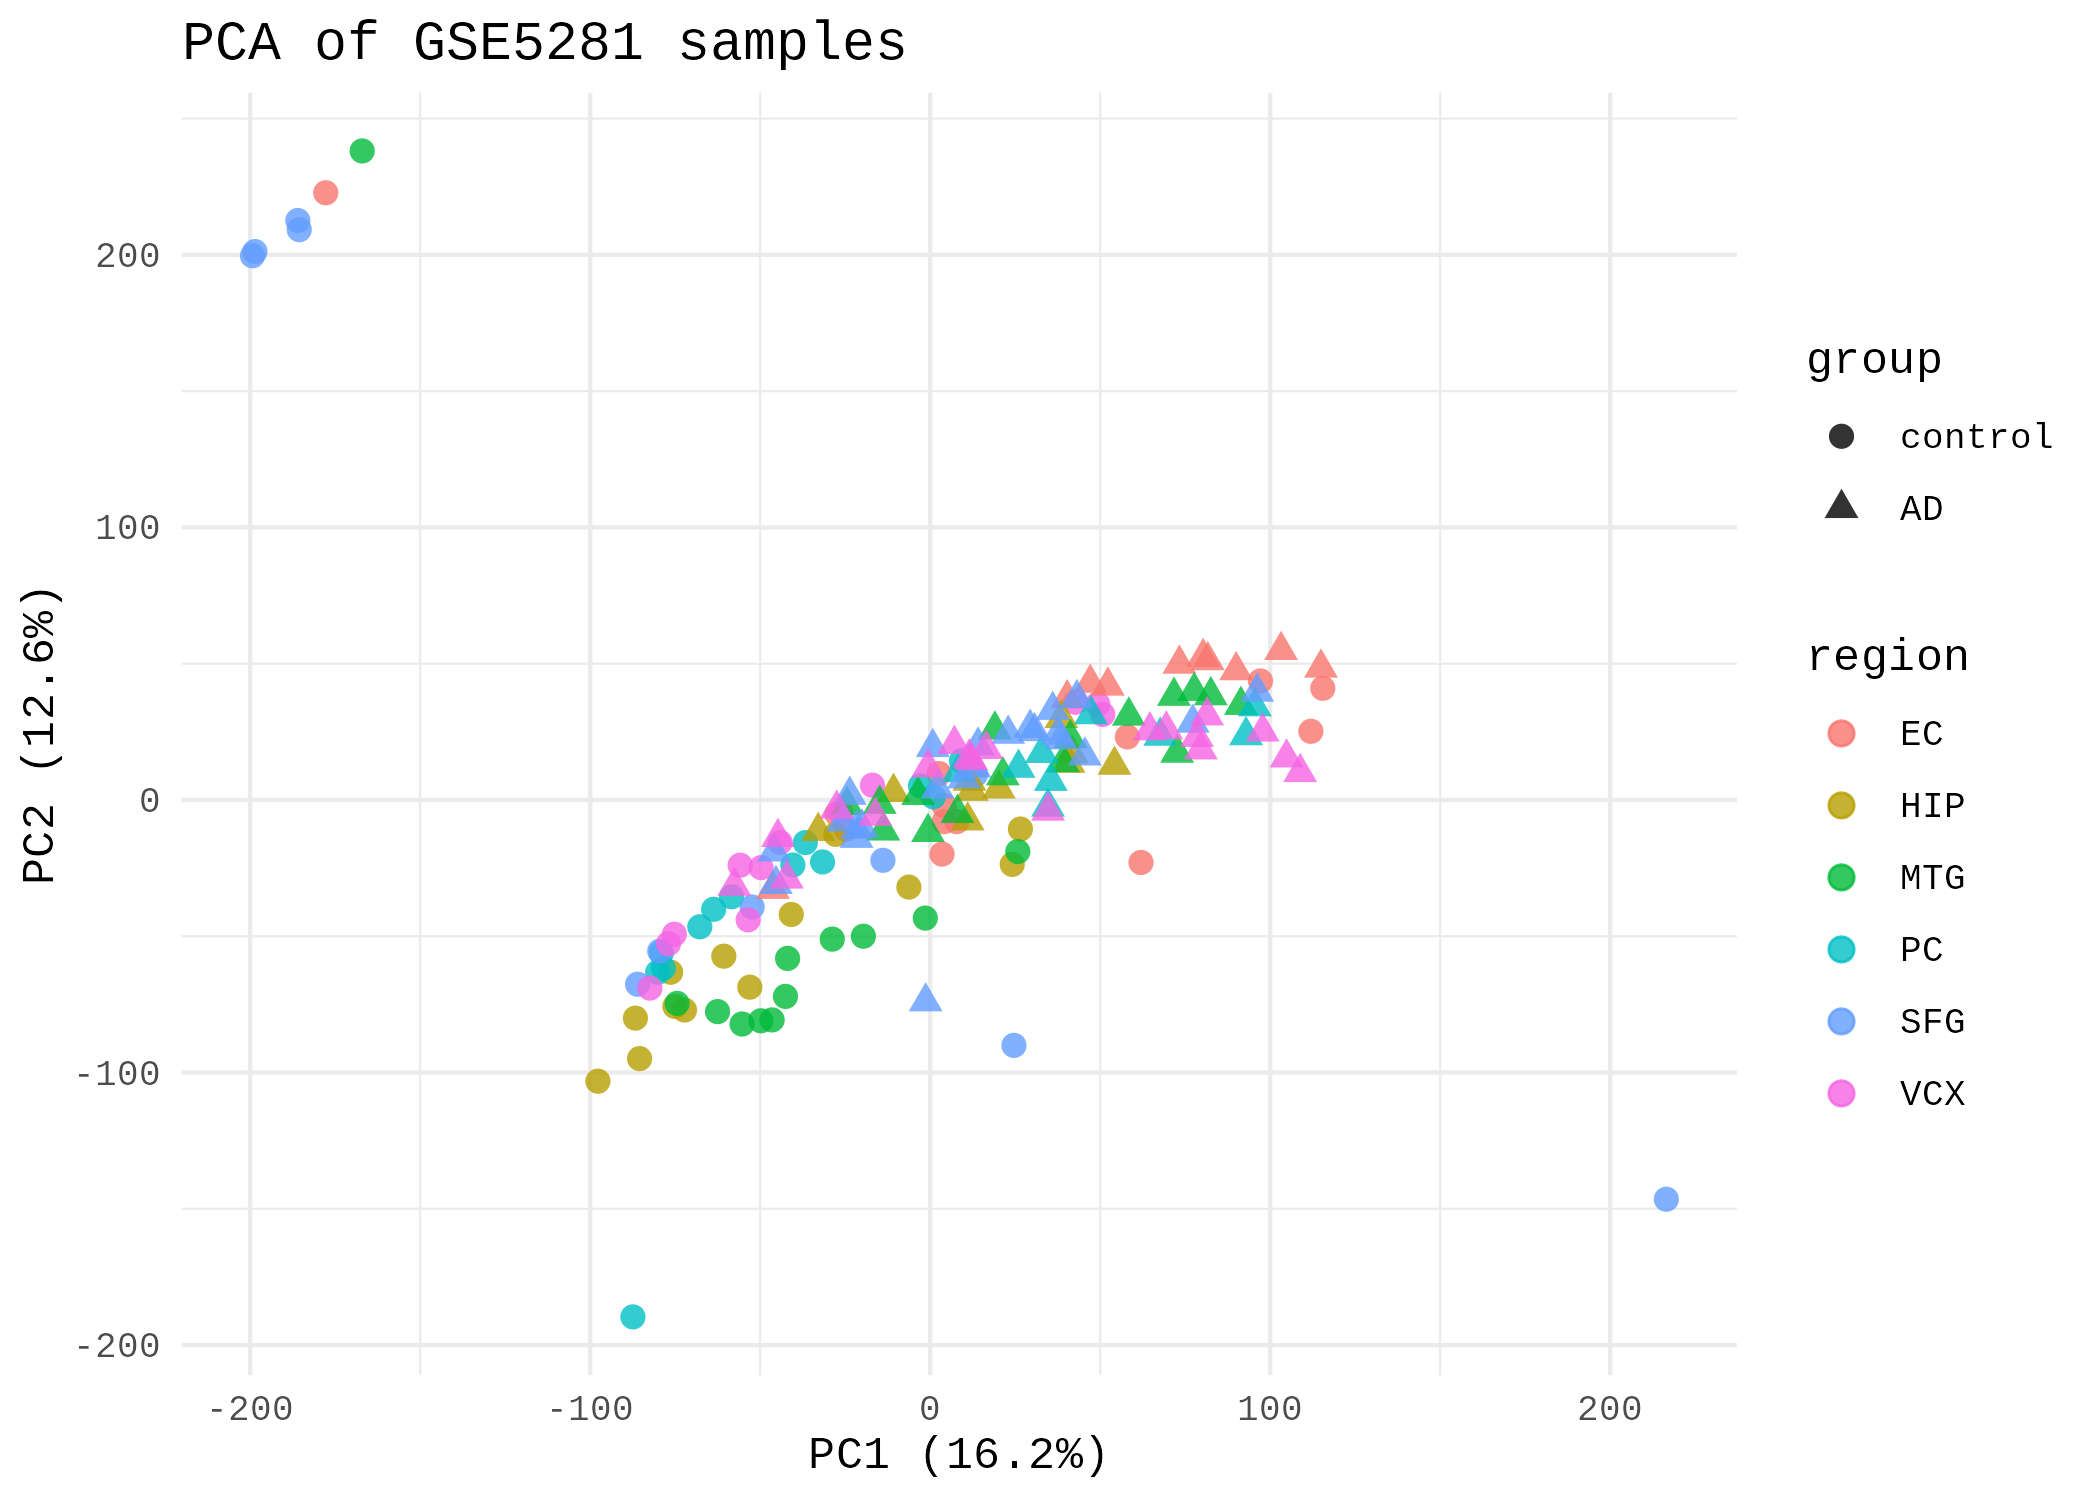

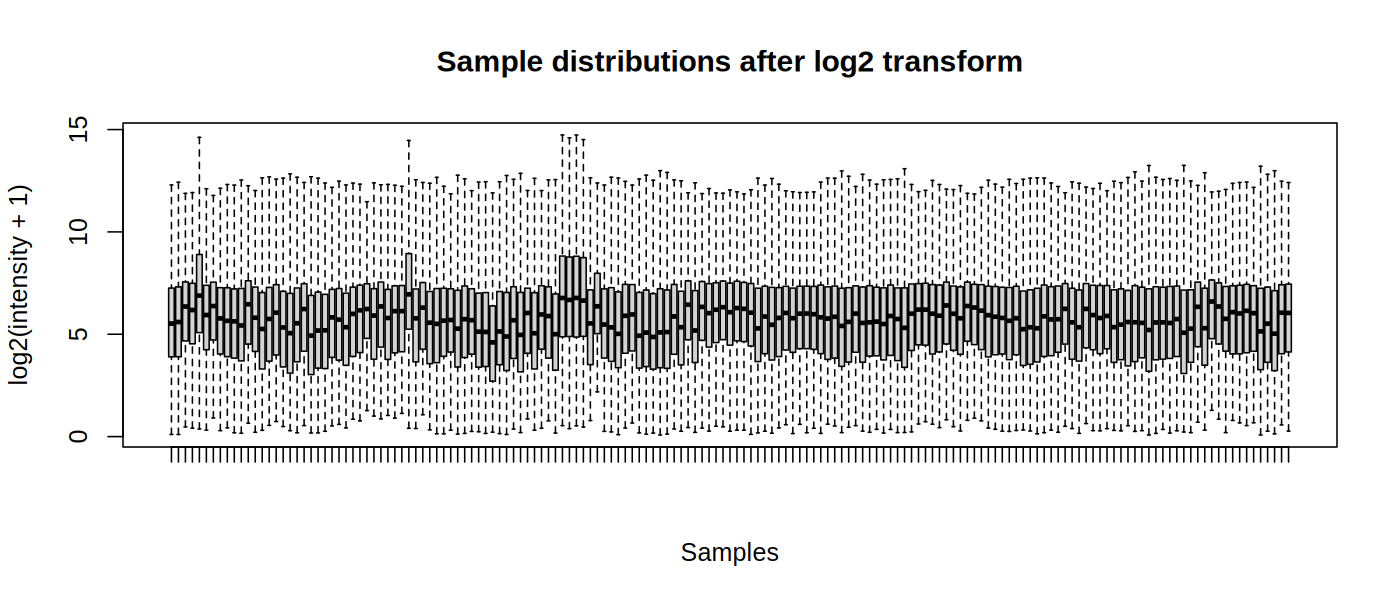

In [7]:
setwd("/content")
library(limma); library(IRdisplay)
d <- readRDS("checkpoints/data.rds")
de <- readRDS("checkpoints/de_results.rds")
res_B <- de$res_B

# 1. Array-level medians by group and region (a gap between groups would suggest a normalisation or quality problem)
arr_med <- apply(d$expr_log, 2, median)
print(tapply(arr_med, d$group, summary))
print(round(tapply(arr_med, d$region, mean), 2))

# 2. Direction of the significant probes in Model B
sig <- res_B$adj.P.Val < 0.05
cat("Significant probes higher in AD:", sum(sig & res_B$logFC > 0), "\n")
cat("Significant probes lower in AD:", sum(sig & res_B$logFC < 0), "\n")
print(summary(res_B$logFC))

# 3. How much of the first PCs is region versus group
pca <- prcomp(t(d$expr_filt), scale. = TRUE)
for (i in 1:3) {
  cat("PC", i, " R2 with region:", round(summary(lm(pca$x[, i] ~ d$region))$r.squared, 2),
      " R2 with group:", round(summary(lm(pca$x[, i] ~ d$group))$r.squared, 2), "\n")
}

# 4. Show the two QC figures
display_png(file = "figures/pca_by_region_and_group.png")
display_png(file = "figures/qc_sample_distributions.png")

In [8]:
system("zip -r outputs.zip results figures")

In [9]:
setwd("/content")
library(limma)
d <- readRDS("checkpoints/data.rds")
expr_log <- d$expr_log; group <- d$group; region <- d$region
meta <- data.frame(group = group, region = region)

# 1. Flag outlier arrays (robust z-scores of each array's median and upper quartile)
arr_med <- apply(expr_log, 2, median)
arr_q75 <- apply(expr_log, 2, quantile, probs = 0.75)
rz <- function(x) (x - median(x)) / mad(x)
for (t in c(3, 4, 5)) {
  cat("Arrays flagged at threshold", t, ":", sum(abs(rz(arr_med)) > t | abs(rz(arr_q75)) > t), "\n")
}
flag <- abs(rz(arr_med)) > 4 | abs(rz(arr_q75)) > 4
print(data.frame(sample = colnames(expr_log)[flag], group = group[flag], region = region[flag],
                 median = round(arr_med[flag], 2), q75 = round(arr_q75[flag], 2),
                 z_med = round(rz(arr_med)[flag], 1), z_q75 = round(rz(arr_q75)[flag], 1)))

# 2. Re-run the analysis four ways
run_de <- function(expr, meta, lfc = 0) {
  design <- model.matrix(~ region + group, data = meta)
  fit <- lmFit(expr, design)
  if (lfc > 0) { fit <- treat(fit, lfc = lfc); topTreat(fit, coef = "groupAD", number = Inf, sort.by = "P") }
  else { fit <- eBayes(fit); topTable(fit, coef = "groupAD", number = Inf, sort.by = "P") }
}
filt <- function(x) x[rowMeans(x) > quantile(rowMeans(x), 0.5), ]
lc <- log2(1.5)
keep <- !flag
meta_k <- droplevels(meta[keep, ])

res_B <- readRDS("checkpoints/de_results.rds")$res_B            # all arrays
res_C <- run_de(filt(expr_log[, keep]), meta_k)                 # outliers removed
expr_D <- filt(normalizeBetweenArrays(expr_log[, keep], method = "quantile"))
res_D <- run_de(expr_D, meta_k)                                 # plus quantile normalisation
res_E <- run_de(expr_D, meta_k, lfc = lc)                       # plus a test against a 1.5-fold minimum

sets <- list(
  B_all_arrays       = rownames(res_B)[res_B$adj.P.Val < 0.05 & abs(res_B$logFC) > lc],
  C_outliers_removed = rownames(res_C)[res_C$adj.P.Val < 0.05 & abs(res_C$logFC) > lc],
  D_plus_quantile    = rownames(res_D)[res_D$adj.P.Val < 0.05 & abs(res_D$logFC) > lc],
  E_plus_treat       = rownames(res_E)[res_E$adj.P.Val < 0.05])
print(data.frame(model = names(sets), n_significant = sapply(sets, length), row.names = NULL))
cat("Overlap B and D:", length(intersect(sets[[1]], sets[[3]])), "\n")
cat("Overlap D and E:", length(intersect(sets[[3]], sets[[4]])), "\n")
cat("Overlap B and E:", length(intersect(sets[[1]], sets[[4]])), "\n")

saveRDS(list(flag = flag, res_C = res_C, res_D = res_D, res_E = res_E), "checkpoints/sensitivity.rds")
cat("Sensitivity check finished\n")

Arrays flagged at threshold 3 : 8 
Arrays flagged at threshold 4 : 8 
Arrays flagged at threshold 5 : 7 
             sample   group region median  q75 z_med z_q75
GSM119619 GSM119619 control     EC   6.89 8.90   2.5  10.5
GSM119649 GSM119649 control    MTG   6.95 8.94   2.7  10.8
GSM119661 GSM119661 control     PC   4.60 6.39  -2.7  -6.2
GSM119671 GSM119671 control    SFG   6.77 8.82   2.2  10.0
GSM119672 GSM119672 control    SFG   6.68 8.77   2.0   9.7
GSM119673 GSM119673 control    SFG   6.77 8.81   2.3   9.9
GSM119674 GSM119674 control    SFG   6.65 8.74   2.0   9.5
GSM119676 GSM119676 control    SFG   6.36 7.98   1.3   4.4
               model n_significant
1       B_all_arrays          8953
2 C_outliers_removed          9157
3    D_plus_quantile          8544
4       E_plus_treat          2353
Overlap B and D: 7507 
Overlap D and E: 2353 
Overlap B and E: 2338 
Sensitivity check finished


In [10]:
setwd("/content")
library(limma)
d <- readRDS("checkpoints/data.rds"); s <- readRDS("checkpoints/sensitivity.rds")
expr_log <- d$expr_log; group <- d$group; region <- d$region; flag <- s$flag
res_E <- s$res_E
lc <- log2(1.5)

meta_all <- data.frame(group = group, region = region,
                       flagged = factor(ifelse(flag, "flagged", "ok")))
expr_Q <- normalizeBetweenArrays(expr_log, method = "quantile")
expr_Qf <- expr_Q[rowMeans(expr_Q) > quantile(rowMeans(expr_Q), 0.5), ]
design_F <- model.matrix(~ region + flagged + group, data = meta_all)
fit_F <- treat(lmFit(expr_Qf, design_F), lfc = lc)
res_F <- topTreat(fit_F, coef = "groupAD", number = Inf, sort.by = "P")

sig_E <- rownames(res_E)[res_E$adj.P.Val < 0.05]
sig_F <- rownames(res_F)[res_F$adj.P.Val < 0.05]
cat("Model E (flagged arrays removed):", length(sig_E), "\n")
cat("Model F (all arrays, flagged-array covariate):", length(sig_F), "\n")
cat("Overlap E and F:", length(intersect(sig_E, sig_F)), "\n")
common <- intersect(rownames(res_E), rownames(res_F))
cat("Correlation of log fold changes, E vs F:",
    round(cor(res_E[common, "logFC"], res_F[common, "logFC"]), 3), "\n")
saveRDS(res_F, "checkpoints/res_F.rds")
cat("Model F finished\n")

Model E (flagged arrays removed): 2353 
Model F (all arrays, flagged-array covariate): 2141 
Overlap E and F: 2120 
Correlation of log fold changes, E vs F: 1 
Model F finished


In [11]:
system("zip -r outputs.zip results figures checkpoints")

In [12]:
setwd("/content")
library(GEOquery); library(limma); library(ggplot2); library(pheatmap)
library(clusterProfiler); library(org.Hs.eg.db)

d <- readRDS("checkpoints/data.rds"); s <- readRDS("checkpoints/sensitivity.rds")
de <- readRDS("checkpoints/de_results.rds"); res_F <- readRDS("checkpoints/res_F.rds")
res_A <- de$res_A; res_B <- de$res_B; res_E <- s$res_E; flag <- s$flag
expr_log <- d$expr_log; group <- d$group; region <- d$region
keep <- !flag
group_k <- droplevels(group[keep]); region_k <- droplevels(region[keep])
lc <- log2(1.5)

# Rebuild the Model E expression matrix (identical steps to the sensitivity check)
expr_Q <- normalizeBetweenArrays(expr_log[, keep], method = "quantile")
expr_D <- expr_Q[rowMeans(expr_Q) > quantile(rowMeans(expr_Q), 0.5), ]
stopifnot(all(rownames(res_E) %in% rownames(expr_D)))

# Probe to gene symbol (first listed gene for probes mapping to several genes)
gpl <- getGEO("GPL570", AnnotGPL = TRUE)
platform_data <- Table(gpl)[, c("ID", "Gene symbol")]
rm(gpl); gc()
raw_symbol <- setNames(platform_data$`Gene symbol`, platform_data$ID)
id_to_symbol <- setNames(sub("\\s*///.*$", "", raw_symbol), names(raw_symbol))

# Significant sets
sig_A <- res_A[res_A$adj.P.Val < 0.05 & abs(res_A$logFC) > 1, ]
sig_A$gene_symbol <- raw_symbol[rownames(sig_A)]
sig_E <- res_E[res_E$adj.P.Val < 0.05, ]
sig_E$gene_symbol <- id_to_symbol[rownames(sig_E)]
write.csv(res_E, "results/de_results_modelE_all.csv")
write.csv(sig_E, "results/sig_genes_modelE.csv")
write.csv(sig_A, "results/sig_genes_with_symbols.csv")
write.csv(data.frame(sample = colnames(expr_log)[flag], group = group[flag], region = region[flag]),
          "results/qc_flagged_arrays.csv", row.names = FALSE)

# Sensitivity summary
n_sig_lfc <- function(r) sum(r$adj.P.Val < 0.05 & abs(r$logFC) > lc)
sens <- data.frame(
  model = c("A original (group only, all probes, |log2FC| > 1)",
            "B region-adjusted, all arrays, |log2FC| > log2(1.5)",
            "C B with flagged arrays removed",
            "D C with quantile normalisation",
            "E D tested against 1.5-fold minimum (primary)",
            "F E with all arrays and a flagged-array covariate"),
  n_significant = c(nrow(sig_A), n_sig_lfc(res_B), n_sig_lfc(s$res_C), n_sig_lfc(s$res_D),
                    nrow(sig_E), sum(res_F$adj.P.Val < 0.05)))
write.csv(sens, "results/sensitivity_summary.csv", row.names = FALSE)
print(sens)

# Volcano plot
res_E$significant <- ifelse(res_E$adj.P.Val < 0.05, "Significant", "Not significant")
p_volcano <- ggplot(res_E, aes(x = logFC, y = -log10(P.Value), colour = significant)) +
  geom_point(alpha = 0.5) +
  scale_colour_manual(values = c("Significant" = "red", "Not significant" = "grey")) +
  labs(title = "AD vs control (GSE5281, region-adjusted, 153 arrays)",
       x = "log2 fold change (AD relative to control)", y = "-log10 p-value", colour = "") +
  theme_minimal()
ggsave("figures/volcano_plot_AD_vs_control.png", plot = p_volcano, width = 7, height = 5, dpi = 300)

# Heatmap, top 30
top30 <- rownames(sig_E)[1:30]
heat <- expr_D[top30, ]
lab <- id_to_symbol[top30]
rownames(heat) <- make.unique(ifelse(is.na(lab) | lab == "", top30, lab))
ann <- data.frame(Group = group_k, Region = region_k); rownames(ann) <- colnames(expr_D)
pheatmap(heat, annotation_col = ann, show_colnames = FALSE, scale = "row",
         main = "Top 30 differentially expressed probes, AD vs control",
         filename = "figures/heatmap_top30_genes.png", width = 9, height = 7)

# GO enrichment, background = genes on the array
universe <- unique(id_to_symbol[rownames(expr_D)])
universe <- universe[!is.na(universe) & universe != ""]
run_go <- function(genes, label) {
  genes <- unique(genes[!is.na(genes) & genes != ""])
  if (length(genes) < 10) { message("Too few genes for ", label); return(NULL) }
  ego <- enrichGO(gene = genes, universe = universe, OrgDb = org.Hs.eg.db, keyType = "SYMBOL",
                  ont = "BP", pAdjustMethod = "BH", pvalueCutoff = 0.05, qvalueCutoff = 0.05)
  if (is.null(ego) || nrow(as.data.frame(ego)) == 0) { message("No enriched terms for ", label); return(NULL) }
  write.csv(as.data.frame(ego), paste0("results/go_enrichment_", label, ".csv"), row.names = FALSE)
  p <- dotplot(ego, showCategory = 15) + ggtitle(paste("Top enriched biological processes,", label))
  ggsave(paste0("figures/go_enrichment_dotplot_", label, ".png"), plot = p, width = 8, height = 6, dpi = 300)
  ego
}
go_all  <- run_go(sig_E$gene_symbol, "all_DEGs")
go_up   <- run_go(sig_E$gene_symbol[sig_E$logFC > 0], "higher_in_AD")
go_down <- run_go(sig_E$gene_symbol[sig_E$logFC < 0], "lower_in_AD")
for (nm in c("go_all", "go_up", "go_down")) {
  g <- get(nm)
  if (!is.null(g)) { cat("\n", nm, "top terms\n"); print(head(as.data.frame(g)[, c("Description", "p.adjust")], 8)) }
}

# Gene list for drug mining
gene_list <- data.frame(gene = sig_E$gene_symbol, logFC = sig_E$logFC, adj.P.Val = sig_E$adj.P.Val)
gene_list <- gene_list[!is.na(gene_list$gene) & gene_list$gene != "", ]
gene_list <- gene_list[!duplicated(gene_list$gene), ]
write.csv(gene_list, "results/gene_list_for_drug_mining.csv", row.names = FALSE)

summary_lines <- c(
  paste("Arrays used:", sum(keep), "(AD", sum(group_k == "AD"), ", control", sum(group_k == "control"), ")"),
  paste("Probes tested:", nrow(res_E)),
  paste("Significant probes (Model E):", nrow(sig_E)),
  paste("Higher in AD:", sum(sig_E$logFC > 0), " Lower in AD:", sum(sig_E$logFC < 0)),
  paste("Unique genes in drug-mining list:", nrow(gene_list)),
  paste("Probes shared by Model A and Model E:", length(intersect(rownames(sig_A), rownames(sig_E)))))
writeLines(summary_lines, "results/summary_counts.txt")
writeLines(capture.output(sessionInfo()), "results/sessionInfo.txt")
cat("\n"); cat(summary_lines, sep = "\n"); cat("Stage 3 finished\n")



clusterProfiler v4.20.3 Learn more at https://yulab-smu.top/contribution-knowledge-mining/

Please cite:

T Wu, E Hu, S Xu, M Chen, P Guo, Z Dai, T Feng, L Zhou, W Tang, L Zhan,
X Fu, S Liu, X Bo, and G Yu. clusterProfiler 4.0: A universal
enrichment tool for interpreting omics data. The Innovation. 2021,
2(3):100141


Attaching package: ‘clusterProfiler’


The following object is masked from ‘package:stats’:

    filter


Loading required package: AnnotationDbi

Loading required package: stats4

Loading required package: IRanges

Loading required package: S4Vectors


Attaching package: ‘S4Vectors’


The following object is masked from ‘package:clusterProfiler’:

    rename


The following object is masked from ‘package:utils’:

    findMatches


The following objects are masked from ‘package:base’:

    expand.grid, I, unname



Attaching package: ‘IRanges’


The following object is masked from ‘package:clusterProfiler’:

    slice



Attaching package: ‘AnnotationDbi’


The followi

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,9014915,481.5,16817750,898.2,12346060,659.4
Vcells,63126055,481.7,142769750,1089.3,142766402,1089.3


                                                model n_significant
1   A original (group only, all probes, |log2FC| > 1)          2972
2 B region-adjusted, all arrays, |log2FC| > log2(1.5)          8953
3                     C B with flagged arrays removed          9157
4                     D C with quantile normalisation          8544
5       E D tested against 1.5-fold minimum (primary)          2353
6   F E with all arrays and a flagged-array covariate          2141


'select()' returned 1:1 mapping between keys and columns

Warning message in bitr(gene, fromType = fromType, toType = "ENTREZID", OrgDb = OrgDb):
“6.95% of input gene IDs are fail to map...”
'select()' returned 1:many mapping between keys and columns

Warning message in bitr(gene, fromType = fromType, toType = "ENTREZID", OrgDb = OrgDb):
“8.91% of input gene IDs are fail to map...”
'select()' returned 1:1 mapping between keys and columns

Warning message in bitr(gene, fromType = fromType, toType = "ENTREZID", OrgDb = OrgDb):
“7.74% of input gene IDs are fail to map...”
'select()' returned 1:many mapping between keys and columns

Warning message in bitr(gene, fromType = fromType, toType = "ENTREZID", OrgDb = OrgDb):
“8.91% of input gene IDs are fail to map...”
'select()' returned 1:1 mapping between keys and columns

Warning message in bitr(gene, fromType = fromType, toType = "ENTREZID", OrgDb = OrgDb):
“6.27% of input gene IDs are fail to map...”
'select()' returned 1:many mapping betw


 go_all top terms
                                                           Description
GO:0009060                                         aerobic respiration
GO:0045333                                        cellular respiration
GO:0009144            purine nucleoside triphosphate metabolic process
GO:0010499 proteasomal ubiquitin-independent protein catabolic process
GO:0009205        purine ribonucleoside triphosphate metabolic process
GO:0019725                                        cellular homeostasis
GO:1902600                              proton transmembrane transport
GO:0099003                       vesicle-mediated transport in synapse
             p.adjust
GO:0009060 0.00151331
GO:0045333 0.01425903
GO:0009144 0.01425903
GO:0010499 0.01425903
GO:0009205 0.01425903
GO:0019725 0.01611781
GO:1902600 0.01633709
GO:0099003 0.01638934

 go_up top terms
                                           Description    p.adjust
GO:0048729                        tissue morphogenesis 0.00

In [13]:
system("zip -r outputs.zip results figures checkpoints")

In [14]:
list.files("/content/results")

[1] "de_results_modelA_all.csv"      "de_results_modelB_all.csv"     
 [3] "de_results_modelE_all.csv"      "gene_list_for_drug_mining.csv" 
 [5] "go_enrichment_all_DEGs.csv"     "go_enrichment_higher_in_AD.csv"
 [7] "go_enrichment_lower_in_AD.csv"  "qc_flagged_arrays.csv"         
 [9] "sensitivity_summary.csv"        "sessionInfo.txt"               
[11] "sig_genes_modelE.csv"           "sig_genes_with_symbols.csv"    
[13] "summary_counts.txt"

In [15]:
setwd("/content")
py <- r"---(
import datetime
import pandas as pd
import requests

genes_df = pd.read_csv("results/gene_list_for_drug_mining.csv")
top = genes_df.head(50)
genes_top50 = top["gene"].tolist()

url = "https://dgidb.org/api/graphql"
query = """
query genes($names: [String!]) {
  genes(names: $names) {
    nodes {
      name
      interactions {
        drug { name }
        interactionScore
        interactionTypes { type }
      }
    }
  }
}
"""
response = requests.post(url, json={"query": query, "variables": {"names": genes_top50}}, timeout=30)
response.raise_for_status()
data = response.json()
if "errors" in data:
    raise RuntimeError(data["errors"])

nodes = data["data"]["genes"]["nodes"]
rows = []
for node in nodes:
    for inter in node["interactions"]:
        types = ", ".join(t["type"] for t in inter["interactionTypes"]) if inter["interactionTypes"] else "unspecified"
        rows.append({"gene": node["name"], "drug": inter["drug"]["name"],
                     "interaction_type": types, "score": inter["interactionScore"]})

df = pd.DataFrame(rows)
df = df.merge(top[["gene", "logFC", "adj.P.Val"]], on="gene", how="left")
df["direction_in_AD"] = df["logFC"].apply(lambda x: "higher in AD" if x > 0 else "lower in AD")
df = df.sort_values(by="score", ascending=False)
df.to_csv("results/drug_gene_interactions.csv", index=False)

not_found = sorted(set(genes_top50) - {n["name"] for n in nodes})
print("Queried DGIdb on", datetime.date.today())
print("Total interactions found:", len(df))
print("Genes with at least one known drug interaction:", df["gene"].nunique())
print("Genes not found in DGIdb:", not_found)
print(df.head(20).to_string())
)---"
writeLines(py, "drug_target_mining.py")
cat(system("python3 drug_target_mining.py 2>&1", intern = TRUE), sep = "\n")

Queried DGIdb on 2026-10-25
Total interactions found: 457
Genes with at least one known drug interaction: 20
Genes not found in DGIdb: ['AMER2', 'ANKRD36', 'ANP32B', 'ATP5C1', 'C1orf61', 'CD2BP2', 'FBXO32', 'LOC100506248', 'LOC106146153', 'LOC202181', 'LOC441155', 'MIR612', 'NSUN6', 'PNISR', 'SEC62', 'SRRM2', 'TNPO1']
       gene                    drug interaction_type      score     logFC     adj.P.Val direction_in_AD
23    CDC37        SODIUM MOLYBDATE      unspecified  46.822735 -2.195780  1.409580e-08     lower in AD
393     PGF                  TB-403        inhibitor  46.822735  1.686702  3.487166e-08    higher in AD
439   ITPKB                  GNF362        inhibitor  15.607578  2.454105  4.202628e-11    higher in AD
440  SLC5A3               PHLORIZIN        inhibitor  11.705684  2.004202  2.644852e-09    higher in AD
22    CDC37            GELDANAMYCIN      unspecified  11.705684 -2.195780  1.409580e-08     lower in AD
21     LIFR              EMFILERMIN      unspecified  10

In [16]:
setwd("/content")
library(GEOquery); library(limma)
s <- readRDS("checkpoints/sensitivity.rds"); res_E <- s$res_E

collapse_gene <- function(res, symbols) {
  res$gene <- symbols[rownames(res)]
  res <- res[!is.na(res$gene) & res$gene != "", ]
  res <- res[order(res$P.Value), ]
  res[!duplicated(res$gene), ]
}

# Brain (primary analysis) at gene level
gpl570 <- getGEO("GPL570", AnnotGPL = TRUE)
p570 <- Table(gpl570)[, c("ID", "Gene symbol")]; rm(gpl570)
sym570 <- setNames(sub("\\s*///.*$", "", p570$`Gene symbol`), p570$ID)
brain <- collapse_gene(res_E, sym570)

# Blood, GSE63060 (AD vs control only)
gse2 <- getGEO("GSE63060", GSEMatrix = TRUE)
expr2 <- exprs(gse2[[1]]); meta2 <- pData(gse2[[1]]); rm(gse2)
keep <- meta2$`status:ch1` %in% c("AD", "CTL")
expr2 <- expr2[, keep]; meta2 <- meta2[keep, ]
grp2 <- factor(ifelse(meta2$`status:ch1` == "AD", "AD", "control"), levels = c("control", "AD"))
print(table(grp2)); print(summary(as.vector(expr2)))
res2 <- topTable(eBayes(lmFit(expr2, model.matrix(~ grp2))), coef = 2, number = Inf, sort.by = "P")
gpl2 <- getGEO("GPL6947", AnnotGPL = TRUE)
p6947 <- Table(gpl2)[, c("ID", "Gene symbol")]; rm(gpl2)
sym6947 <- setNames(sub("\\s*///.*$", "", p6947$`Gene symbol`), p6947$ID)
blood <- collapse_gene(res2, sym6947)

# Compare across all shared genes
common <- intersect(brain$gene, blood$gene)
b <- brain[match(common, brain$gene), ]; bl <- blood[match(common, blood$gene), ]
sig <- b$adj.P.Val < 0.05
ct <- cor.test(b$t, bl$t, method = "spearman")
agree <- sign(b$logFC[sig]) == sign(bl$logFC[sig])
bt <- binom.test(sum(agree), length(agree), 0.5)
tt <- setNames(bl$t, common)
p_up <- geneSetTest(sig & b$logFC > 0, tt, alternative = "up")
p_dn <- geneSetTest(sig & b$logFC < 0, tt, alternative = "down")
blood_sig <- blood$gene[blood$adj.P.Val < 0.05 & abs(blood$logFC) > 1]

lines <- c(
  paste("Genes measured in both datasets:", length(common)),
  paste("Blood arrays:", ncol(expr2), "(AD", sum(grp2 == "AD"), ", control", sum(grp2 == "control"), ")"),
  paste("Spearman rho, brain t vs blood t:", round(ct$estimate, 3), " p =", signif(ct$p.value, 3)),
  paste("Brain-significant genes in both datasets:", sum(sig), "; same direction in blood:", sum(agree),
        "(", round(100 * mean(agree), 1), "%), binomial p =", signif(bt$p.value, 3)),
  paste("Brain-higher genes rank higher in AD blood, p =", signif(p_up, 3)),
  paste("Brain-lower genes rank lower in AD blood, p =", signif(p_dn, 3)),
  paste("Legacy check, blood genes (adj.P < 0.05, |log2FC| > 1):", length(blood_sig),
        "; shared with brain primary set:", length(intersect(blood_sig, b$gene[sig]))))
writeLines(lines, "results/validation_summary.txt")
cat(lines, sep = "\n"); cat("Validation finished\n")

Using locally cached version of GPL570 found here:
/tmp/RtmpZWsRAh/GPL570.annot.gz 

Found 1 file(s)

GSE63060_series_matrix.txt.gz



grp2
control      AD 
    104     145 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  7.204   7.451   7.543   7.912   7.854  15.050 


Warning message in cor.test.default(b$t, bl$t, method = "spearman"):
“cannot compute exact p-value with ties”


Genes measured in both datasets: 11762
Blood arrays: 249 (AD 145 , control 104 )
Spearman rho, brain t vs blood t: 0.131  p = 2.24e-46
Brain-significant genes in both datasets: 1415 ; same direction in blood: 796 ( 56.3 %), binomial p = 2.81e-06
Brain-higher genes rank higher in AD blood, p = 0.00128
Brain-lower genes rank lower in AD blood, p = 4.44e-13
Legacy check, blood genes (adj.P < 0.05, |log2FC| > 1): 3 ; shared with brain primary set: 0
Validation finished


In [17]:
system("cd /content && zip -r outputs.zip results figures checkpoints drug_target_mining.py")

In [18]:
setwd("/content")
library(limma)
if (!exists("blood") || !exists("sym570") || !exists("collapse_gene"))
  stop("Run the validation cell from my last message again first, then run this one.")
s <- readRDS("checkpoints/sensitivity.rds")

# Corrected validation, standard moderated t from Model D
brainD <- collapse_gene(s$res_D, sym570)
brainE <- collapse_gene(s$res_E, sym570)
common <- intersect(brainD$gene, blood$gene)
b <- brainD[match(common, brainD$gene), ]; bl <- blood[match(common, blood$gene), ]
ct_t  <- cor.test(b$t, bl$t, method = "spearman", exact = FALSE)
ct_fc <- cor.test(b$logFC, bl$logFC, method = "spearman", exact = FALSE)
sig <- b$gene %in% brainE$gene[brainE$adj.P.Val < 0.05]
same <- sign(b$logFC) == sign(bl$logFC)
bt <- binom.test(sum(same[sig]), sum(sig), 0.5)
nominal <- sig & bl$P.Value < 0.05
lines <- c(
  paste("Shared genes:", length(common)),
  paste("Spearman rho, moderated t:", round(ct_t$estimate, 3), " p =", signif(ct_t$p.value, 3)),
  paste("Spearman rho, log fold change:", round(ct_fc$estimate, 3), " p =", signif(ct_fc$p.value, 3)),
  paste("Brain-significant genes in both:", sum(sig), "; same direction in blood:", sum(same[sig]),
        "(", round(100 * mean(same[sig]), 1), "%), binomial p =", signif(bt$p.value, 3)),
  paste("Of those, nominally significant in blood (p < 0.05) with the same direction:", sum(nominal & same)))
writeLines(lines, "results/validation_summary_corrected.txt")
cat(lines, sep = "\n")

conc <- data.frame(gene = b$gene, brain_logFC = round(b$logFC, 2),
                   blood_logFC = round(bl$logFC, 2), blood_P = signif(bl$P.Value, 3))[nominal & same, ]
conc <- conc[order(conc$blood_P), ]
write.csv(conc, "results/brain_blood_concordant_genes.csv", row.names = FALSE)
cat("\nTop concordant genes\n"); print(head(conc, 20), row.names = FALSE)

# Direction-aware drug table
dd <- read.csv("results/drug_gene_interactions.csv")
inhib <- grepl("inhibitor|antagonist|blocker|antibody|negative modulator|suppressor", dd$interaction_type, ignore.case = TRUE)
activ <- grepl("agonist|activator|positive modulator|inducer|potentiator", dd$interaction_type, ignore.case = TRUE)
dd$compatible <- (inhib & dd$direction_in_AD == "higher in AD") | (activ & dd$direction_in_AD == "lower in AD")
comp <- dd[dd$compatible, ]; comp <- comp[order(-comp$score), ]
write.csv(comp, "results/drug_gene_direction_compatible.csv", row.names = FALSE)
cat("\nDirection-compatible interactions:", nrow(comp), "across", length(unique(comp$gene)), "genes\n")
print(head(comp[, c("gene", "drug", "interaction_type", "direction_in_AD", "score")], 20), row.names = FALSE)

system("cd /content && zip -r outputs.zip results figures checkpoints drug_target_mining.py")
cat("\nDone, now download outputs.zip from the content folder\n")

Shared genes: 11762
Spearman rho, moderated t: 0.159  p = 1.27e-67
Spearman rho, log fold change: 0.151  p = 4.19e-61
Brain-significant genes in both: 1415 ; same direction in blood: 792 ( 56 %), binomial p = 7.78e-06
Of those, nominally significant in blood (p < 0.05) with the same direction: 367

Top concordant genes
     gene brain_logFC blood_logFC  blood_P
 ATP6V1E1       -1.52       -0.41 5.30e-21
     RPA3       -1.72       -0.43 2.07e-20
    PSMA3       -1.76       -0.41 2.49e-16
    SLIRP       -1.44       -0.68 4.10e-16
   CCDC53       -1.10       -0.39 1.54e-15
   TROVE2        0.88        0.17 9.48e-15
      TXN       -1.25       -0.71 1.74e-14
    PRDX1       -0.92       -0.33 3.70e-14
     SOD1       -0.95       -0.41 5.40e-14
   DNAJC8       -0.89       -0.35 7.73e-14
     NME1       -1.51       -0.34 4.12e-13
    DPY30       -0.99       -0.50 1.49e-12
     STX8       -1.10       -0.21 3.16e-12
    COX7B       -0.89       -0.41 3.90e-12
      LPP        1.35        0.23 